# 09_04 Density Estimation: Histograms, KDE, Gaussian Mixtures and EM

**Learning objectives**
- Estimate a probability density from data with a **histogram**, a **kernel density estimate (KDE)** and a **Gaussian mixture model (GMM)**, and explain the **bias-variance** role of the bin width or bandwidth.
- Derive the **EM algorithm** for a Gaussian mixture, implement it from scratch (1D and multivariate, three covariance structures) and prove it **never decreases the likelihood**.
- Choose the **bandwidth** (Silverman, leave-one-out cross-validation) and the **number of components** (AIC/BIC, held-out likelihood).
- Use a fitted density for **soft clustering** (responsibilities), **synthetic data generation** and **anomaly scoring**.

**Prerequisites:** [03_01 Multivariate normal](../../module_03_multivariate/notebooks/03_01_multivariate_normal.ipynb), [06_01 Maximum likelihood](../../module_06_inference/notebooks/06_01_mle_method_of_moments.ipynb), [08_02 KL divergence](../../module_08_information/notebooks/08_02_kl_js_divergence.ipynb), [09_03 Naive Bayes](09_03_naive_bayes.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
A density $f$ integrates to 1; the likelihood of data $x_1..x_n$ under $f$ is $\prod f(x_i)$. Maximum likelihood fits a parametric family (Module 06); the best model in KL (08_02) maximises the expected log-likelihood. A mixture $f=\sum_k\pi_kf_k$ draws first a component $k\sim\mathrm{Categorical}(\pi)$, then $x\sim f_k$.

## 3. Intuition and story
You have 1,500 customers' monthly spend and no model for it. A **histogram** counts customers in bins, but the picture depends on where the bins start and how wide they are. A **KDE** puts a small bump on each customer and adds the bumps: the width of the bump (the bandwidth) trades smoothness against fidelity. A **Gaussian mixture** goes one step further and says "there are a few kinds of customers, each described by a bell curve", which gives not only a density but also a **segmentation**: for any spend it tells how likely each segment is. The **EM algorithm** fits it by alternating two easy steps: guess which segment each customer belongs to (softly), then re-estimate the segments from those guesses.

## 4. Formal definitions

| Object | Definition |
|---|---|
| **Histogram** | $\hat f(x)=\dfrac{n_{\text{bin}(x)}}{n\,h}$ with bin width $h$ |
| **Kernel density estimate** | $\hat f_h(x)=\dfrac1{nh}\sum_{i=1}^nK\!\Big(\dfrac{x-x_i}h\Big)$, Gaussian kernel $K=\varphi$ |
| **Silverman's rule** | $h=0.9\,\min\{s,\mathrm{IQR}/1.34\}\,n^{-1/5}$ |
| **Gaussian mixture** | $f(x)=\sum_{k=1}^K\pi_k\,N(x;\mu_k,\Sigma_k)$, $\ \pi_k\ge0$, $\sum\pi_k=1$ |
| **Responsibility** | $r_{ik}=P(z_i=k\mid x_i)=\dfrac{\pi_kN(x_i;\mu_k,\Sigma_k)}{\sum_j\pi_jN(x_i;\mu_j,\Sigma_j)}$ |
| **BIC / AIC** | $\mathrm{BIC}=p\ln n-2\ell$, $\ \mathrm{AIC}=2p-2\ell$ ($p$ free parameters) |

**EM for a GMM.** *E-step:* compute $r_{ik}$. *M-step:* with $N_k=\sum_ir_{ik}$: $\ \pi_k=N_k/n$, $\ \mu_k=\frac1{N_k}\sum_ir_{ik}x_i$, $\ \Sigma_k=\frac1{N_k}\sum_ir_{ik}(x_i-\mu_k)(x_i-\mu_k)^\top$. **Parameter count** in $d$ dimensions: full covariance $K-1+Kd+Kd(d+1)/2$, diagonal $K-1+2Kd$, spherical $K-1+Kd+K$.

## 5. Derivations

### 5.1 The bias-variance trade-off of a KDE
For a smooth $f$ and a kernel with variance $\sigma_K^2$, $\ \mathrm{bias}\,\hat f_h(x)\approx\tfrac12h^2\sigma_K^2f''(x)$ and $\ \mathrm{Var}\,\hat f_h(x)\approx\dfrac{R(K)f(x)}{nh}$ with $R(K)=\int K^2$. The integrated squared error $\mathrm{MISE}\approx\tfrac14h^4\sigma_K^4R(f'')+\dfrac{R(K)}{nh}$ is minimised at $h^*\propto n^{-1/5}$, giving MISE $\propto n^{-4/5}$. **In plain words.** A narrow bump follows the sample's noise (high variance), a wide bump flattens real structure (high bias); the best width shrinks slowly, like $n^{-1/5}$, and a KDE converges more slowly than a parametric fit.

### 5.2 EM increases the likelihood
Introduce the hidden segment $z_i$. For any distribution $q(z)$, $\ \ln p(x\mid\theta)=\underbrace{E_q\ln\frac{p(x,z\mid\theta)}{q(z)}}_{\mathcal L(q,\theta)}+\mathrm{KL}\big(q\,\|\,p(z\mid x,\theta)\big)$. The E-step sets $q=p(z\mid x,\theta_{\text{old}})$ (the responsibilities), making the KL zero so $\mathcal L=\ln p(x\mid\theta_{\text{old}})$; the M-step maximises $\mathcal L$ over $\theta$. Since the KL is $\ge0$ at the new $\theta$, $\ \ln p(x\mid\theta_{\text{new}})\ge\mathcal L(q,\theta_{\text{new}})\ge\ln p(x\mid\theta_{\text{old}})$. **In plain words.** Each round first makes the best soft guess about the hidden labels and then improves the parameters given those guesses; the likelihood can only go up, so the algorithm climbs to a (local) maximum.

### 5.3 The M-step is a weighted maximum likelihood
Maximising $\sum_i\sum_kr_{ik}[\ln\pi_k+\ln N(x_i;\mu_k,\Sigma_k)]$ separately gives the weighted proportions, means and covariances above (Lagrange multiplier for $\sum\pi_k=1$). **In plain words.** The M-step is just "compute each segment's share, mean and covariance, counting each customer in proportion to how likely they belong to it".

### 5.4 K-means is the hard, spherical limit
If all $\Sigma_k=\sigma^2I$ with $\sigma\to0$ the responsibilities become 0 or 1 (nearest mean) and the M-step becomes the cluster mean: this is k-means. **In plain words.** K-means assigns each point to a single cluster of equal round shape; a GMM allows overlapping clusters of different shape and size.

### 5.5 Choosing $K$
The likelihood always increases with $K$ (more parameters). BIC penalises $p\ln n$ and is consistent for the true $K$ when the model is right; AIC penalises less and tends to pick larger $K$. **In plain words.** Pick the number of segments beyond which the extra parameters no longer buy a worthwhile improvement in the fit to *new* data.

## 6. Properties and relationships
- **Histogram, KDE and GMM are three points on a scale** from almost no assumptions (and slow convergence) to a strong parametric model.
- **EM finds only local maxima** and a component can collapse onto a single point (likelihood $\to\infty$); use several starts and a variance floor.
- **Identifiability:** components can be permuted (label switching); compare sorted means.
- **Curse of dimensionality:** a KDE needs exponentially more data in high dimension; a GMM with structured covariance scales better.
- **Link to ML and AI:** clustering and customer segmentation, anomaly detection (09_05), generative modelling and synthetic data, initialisation of mixture-density networks, speech and image models (GMM-HMM), the E-step/M-step logic behind VAEs (09_08, ELBO) and topic models.

## 7. KDE and a Gaussian-mixture EM from scratch

A 1D KDE, a general multivariate GMM with full, diagonal or spherical covariances (log-sum-exp for stability, k-means++ style initialisation, variance floor) and a simple k-means.

In [2]:
from scipy.special import logsumexp
def kde(x, data, h): return np.exp(-0.5 * ((x[:, None] - data[None, :]) / h) ** 2).sum(axis=1) / (len(data) * h * np.sqrt(2 * np.pi))
def silverman(d): return 0.9 * min(d.std(ddof=1), stats.iqr(d) / 1.34) * len(d) ** (-0.2)
def logpdf_gauss(X, mu, S):
    d = X.shape[1]; L = np.linalg.cholesky(S); z = np.linalg.solve(L, (X - mu).T); return -0.5 * (z ** 2).sum(axis=0) - np.log(np.diag(L)).sum() - 0.5 * d * np.log(2 * np.pi)
def gmm(X, K, cov="full", iters=300, tol=1e-9, seed=0, reg=1e-6, trace=False):
    X = np.atleast_2d(X.T).T if X.ndim == 1 else X; n, d = X.shape; g = np.random.default_rng(seed); mu = X[g.choice(n, 1)]
    for _ in range(K - 1): D2 = np.min(((X[:, None, :] - mu[None]) ** 2).sum(axis=2), axis=1); mu = np.vstack([mu, X[g.choice(n, p=D2 / D2.sum())]])
    S = np.array([np.cov(X.T).reshape(d, d) + reg * np.eye(d)] * K); pi = np.ones(K) / K; ll_old = -np.inf; hist = []; snaps = []
    for it in range(iters):
        lp = np.column_stack([np.log(pi[k]) + logpdf_gauss(X, mu[k], S[k]) for k in range(K)]); ll = logsumexp(lp, axis=1); R = np.exp(lp - ll[:, None]); L = ll.sum(); hist.append(L)
        if trace: snaps.append((mu.copy(), S.copy(), pi.copy()))
        if abs(L - ll_old) < tol * abs(L): break
        ll_old = L; Nk = R.sum(axis=0); pi = Nk / n; mu = (R.T @ X) / Nk[:, None]
        for k in range(K):
            Z = X - mu[k]; C = (R[:, k, None] * Z).T @ Z / Nk[k]
            if cov == "diag": C = np.diag(np.diag(C))
            if cov == "spherical": C = np.eye(d) * np.trace(C) / d
            S[k] = C + reg * np.eye(d)
    npar = (K - 1) + K * d + (K * d * (d + 1) // 2 if cov == "full" else K * d if cov == "diag" else K)
    return dict(pi=pi, mu=mu, S=S, ll=L, R=R, hist=hist, bic=npar * np.log(n) - 2 * L, aic=2 * npar - 2 * L, npar=npar, snaps=snaps, iters=it + 1)
def gmm_logpdf(X, m): X = np.atleast_2d(X.T).T if X.ndim == 1 else X; return logsumexp(np.column_stack([np.log(m["pi"][k]) + logpdf_gauss(X, m["mu"][k], m["S"][k]) for k in range(len(m["pi"]))]), axis=1)
def kmeans(X, K, seed=0, iters=100):
    g = np.random.default_rng(seed); mu = X[g.choice(len(X), K, replace=False)]
    for _ in range(iters): lab = np.argmin(((X[:, None, :] - mu[None]) ** 2).sum(axis=2), axis=1); mu = np.array([X[lab == k].mean(axis=0) if (lab == k).any() else mu[k] for k in range(K)])
    return lab, mu
g = np.random.default_rng(0); xs = np.concatenate([g.normal(40, 10, 700), g.normal(95, 18, 300)]); m_ = gmm(xs, 2)
print("EM recovers: weights", m_["pi"].round(3), "means", m_["mu"].ravel().round(2), "sds", np.sqrt(m_["S"].ravel()).round(2), "| log-lik", round(m_["ll"], 2), "after", m_["iters"], "iterations")
assert all(np.diff(m_["hist"]) > -1e-8) and abs(np.sort(m_["mu"].ravel())[0] - 40) < 1.5 and abs(np.sort(m_["mu"].ravel())[1] - 95) < 3

EM recovers: weights [0.296 0.704] means [93.44 39.92] sds [16.13 10.07] | log-lik -4430.0 after 19 iterations


## 8. 2D visuals

### 8.1 Histogram: the bin width and the starting point matter
The same 1,000 spend values with three bin widths (too narrow, about right, too wide) and the same width with two different starting points: the picture of a histogram depends on choices that have nothing to do with the data.

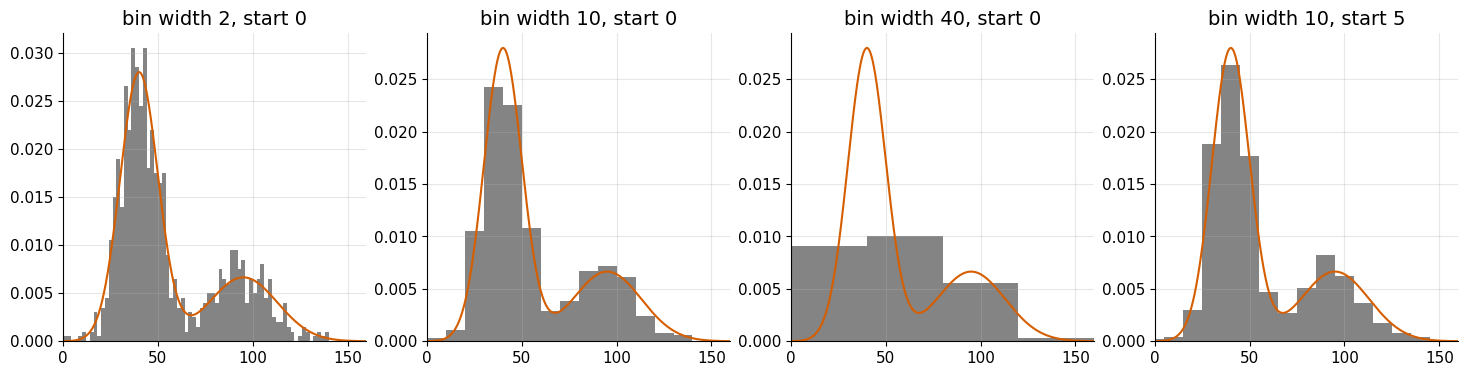

histogram with width 2 has 30 different bar heights (noisy) | with width 40 only 4 non-empty bins (the second mode is lost)


In [3]:
f_true = lambda x: 0.7 * stats.norm.pdf(x, 40, 10) + 0.3 * stats.norm.pdf(x, 95, 18); xg = np.linspace(0, 160, 800); fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (w, start) in zip(axes, [(2, 0), (10, 0), (40, 0), (10, 5)]): ax.hist(xs, bins=np.arange(start - 40 * (start > 0), 170, w), density=True, color=NEUTRAL, alpha=0.8); ax.plot(xg, f_true(xg), color=HIGHLIGHT); ax.set_title(f"bin width {w}, start {start}"); ax.set_xlim(0, 160)
plt.show(); print("histogram with width 2 has", len(np.unique(np.histogram(xs, bins=np.arange(0, 170, 2))[0])), "different bar heights (noisy) | with width 40 only", int((np.histogram(xs, bins=np.arange(0, 170, 40))[0] > 0).sum()), "non-empty bins (the second mode is lost)"); assert (np.histogram(xs, bins=np.arange(0, 170, 40))[0] > 0).sum() <= 4

### 8.2 KDE: one bump per observation and the bandwidth
Left: the KDE is the sum of small Gaussian bumps (shown for 12 points). Right: three bandwidths: too small (spiky), Silverman, too large (the two segments merge).

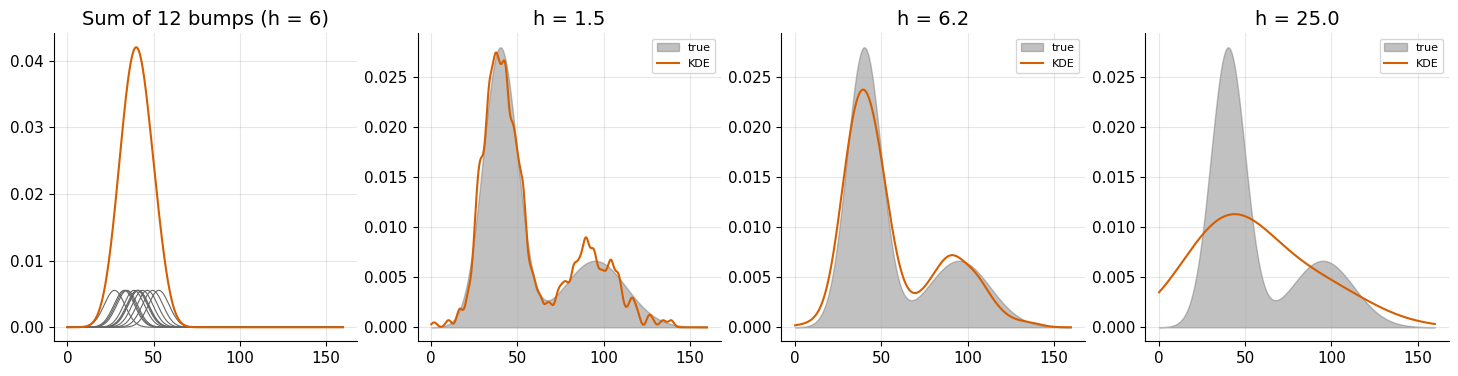

Silverman bandwidth 6.17 | integrated squared error: h = 1.5: 1.46e-04, Silverman: 2.67e-04, h = 25: 4.91e-03


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4)); sm = xs[:12]; xx = np.linspace(0, 160, 800); h_s = silverman(xs)
for v in sm: axes[0].plot(xx, stats.norm.pdf(xx, v, 6) / len(sm), color=NEUTRAL, linewidth=0.8)
axes[0].plot(xx, kde(xx, sm, 6), color=HIGHLIGHT); axes[0].set_title("Sum of 12 bumps (h = 6)")
for ax, h in zip(axes[1:], [1.5, h_s, 25]): ax.fill_between(xx, f_true(xx), color=NEUTRAL, alpha=0.4, label="true"); ax.plot(xx, kde(xx, xs, h), color=HIGHLIGHT, label="KDE"); ax.legend(fontsize=8); ax.set_title(f"h = {h:.1f}")
plt.show(); ise = lambda h: np.trapezoid((kde(xx, xs, h) - f_true(xx)) ** 2, xx); print(f"Silverman bandwidth {h_s:.2f} | integrated squared error: h = 1.5: {ise(1.5):.2e}, Silverman: {ise(h_s):.2e}, h = 25: {ise(25):.2e}"); assert ise(h_s) < ise(25) and ise(1.5) > 0

### 8.3 EM at work
Four snapshots of EM for the two-segment spend data, starting from two poor initial means: the mixture density moves to the data and the log-likelihood increases at every step.

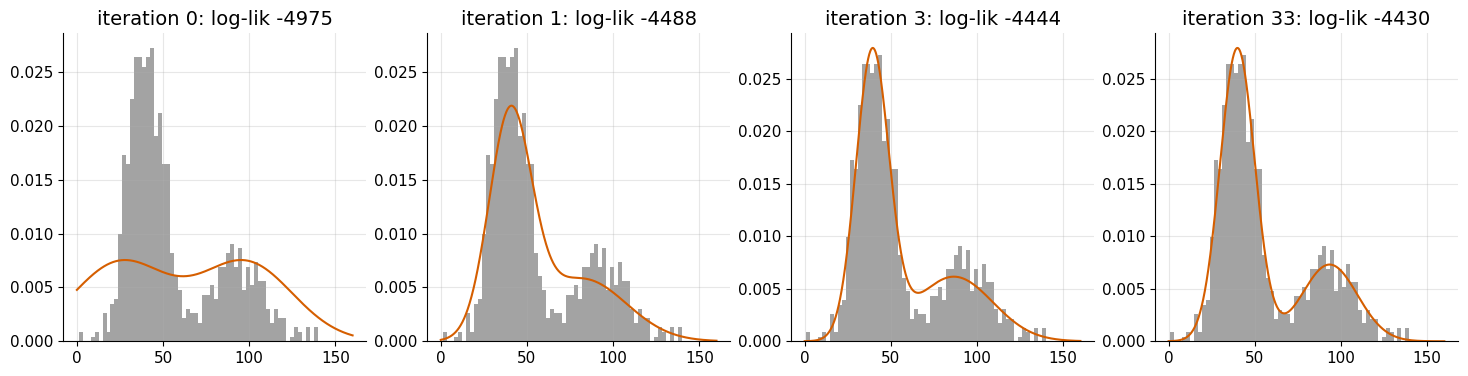

log-likelihood by iteration: [-4975.31 -4487.7  -4450.17 -4443.74 -4441.   -4438.36 -4435.84 -4433.73] ... final -4430.0 after 34 iterations


In [5]:
mt = gmm(xs, 2, trace=True, seed=3, tol=1e-12); steps = [0, 1, 3, len(mt["snaps"]) - 1]; fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, s in zip(axes, steps):
    mu_, S_, pi_ = mt["snaps"][s]; ax.hist(xs, bins=60, density=True, color=NEUTRAL, alpha=0.6); ax.plot(xx, sum(pi_[k] * stats.norm.pdf(xx, mu_[k, 0], np.sqrt(S_[k, 0, 0])) for k in range(2)), color=HIGHLIGHT); ax.set_title(f"iteration {s}: log-lik {mt['hist'][s]:.0f}")
plt.show(); print("log-likelihood by iteration:", np.round(mt["hist"][:8], 2), "... final", round(mt["hist"][-1], 2), "after", mt["iters"], "iterations"); assert all(np.diff(mt["hist"]) > -1e-8)

## 9. 3D visuals

### 9.1 Static: a two-dimensional KDE and a fitted GMM surface
Two features (monthly spend and number of orders) of 1,200 customers from three segments. Left: the bivariate KDE; right: the GMM density with $K=3$ and full covariances.

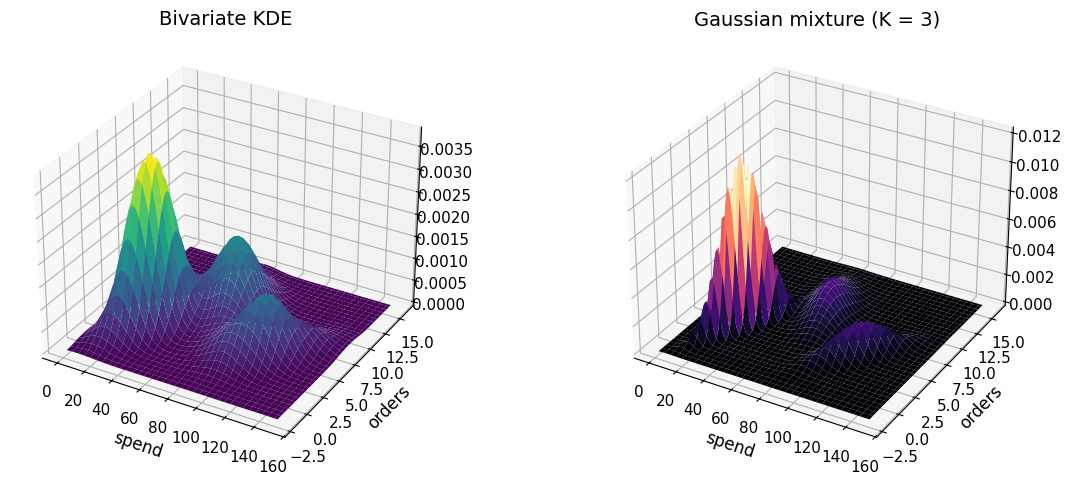

GMM density integrates to 0.9986; EM weights [0.196 0.35  0.454] (truth 0.20, 0.35, 0.45)


In [6]:
g = np.random.default_rng(1); comps = [(0.45, [30, 4], [[60, 12], [12, 3]]), (0.35, [70, 9], [[100, -10], [-10, 6]]), (0.20, [110, 5], [[150, 20], [20, 4]])]
X2 = np.vstack([g.multivariate_normal(m, C, int(1200 * p)) for p, m, C in comps]); lab2 = np.repeat([0, 1, 2], [int(1200 * p) for p, _, _ in comps]); m2 = gmm(X2, 3, seed=2)
G1, G2 = np.meshgrid(np.linspace(0, 150, 70), np.linspace(-2, 16, 70)); pts = np.column_stack([G1.ravel(), G2.ravel()]); hx = [0.9 * X2[:, j].std() * len(X2) ** (-1 / 6) for j in range(2)]
Z_kde = np.array([np.mean(stats.norm.pdf(p[0], X2[:, 0], hx[0]) * stats.norm.pdf(p[1], X2[:, 1], hx[1])) for p in pts]).reshape(G1.shape); Z_gmm = np.exp(gmm_logpdf(pts, m2)).reshape(G1.shape)
fig = plt.figure(figsize=(14, 5.6)); ax = fig.add_subplot(1, 2, 1, projection="3d"); ax.plot_surface(G1, G2, Z_kde, cmap="viridis", edgecolor="none"); ax.set_title("Bivariate KDE"); ax.set_xlabel("spend"); ax.set_ylabel("orders"); ax.view_init(elev=30, azim=-60)
ax = fig.add_subplot(1, 2, 2, projection="3d"); ax.plot_surface(G1, G2, Z_gmm, cmap="magma", edgecolor="none"); ax.set_title("Gaussian mixture (K = 3)"); ax.set_xlabel("spend"); ax.set_ylabel("orders"); ax.view_init(elev=30, azim=-60)
plt.show(); area = np.trapezoid(np.trapezoid(Z_gmm, G2[:, 0], axis=0), G1[0]); print(f"GMM density integrates to {area:.4f}; EM weights {np.sort(m2['pi']).round(3)} (truth 0.20, 0.35, 0.45)"); assert abs(area - 1) < 0.02 and np.abs(np.sort(m2["pi"]) - [0.2, 0.35, 0.45]).max() < 0.04

### 9.2 Interactive Plotly version of 9.1 (GMM surface)

In [7]:
fig = go.Figure(go.Surface(x=G1[0], y=G2[:, 0], z=Z_gmm, colorscale="Magma")); fig.update_layout(title="Gaussian mixture density", width=760, height=560, scene=dict(xaxis_title="spend", yaxis_title="orders", zaxis_title="density")); fig.show()

### 9.3 Static: the log-likelihood surface of a one-dimensional mixture
For the spend data with the component SDs and weights fixed, the log-likelihood is a function of the two means; it has a maximum at the true means and a **mirror twin** (label switching) at the swapped means, plus saddle structure between.

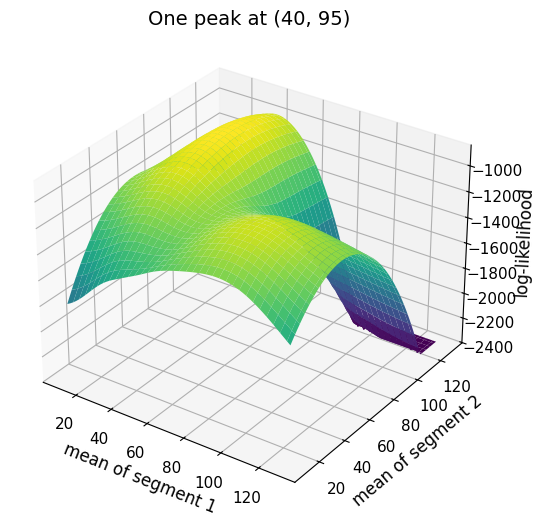

maximum at means 39.6 91.7


In [8]:
m1g, m2g = np.meshgrid(np.linspace(10, 130, 70), np.linspace(10, 130, 70)); LLs = np.zeros_like(m1g)
for i in range(70):
    for j in range(70): LLs[i, j] = np.sum(np.log(0.7 * stats.norm.pdf(xs[::5], m1g[i, j], 10) + 0.3 * stats.norm.pdf(xs[::5], m2g[i, j], 18)))
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(m1g, m2g, np.maximum(LLs, LLs.max() - 1500), cmap="viridis", edgecolor="none"); ax.set_xlabel("mean of segment 1"); ax.set_ylabel("mean of segment 2"); ax.set_zlabel("log-likelihood"); ax.set_title("One peak at (40, 95)"); ax.view_init(elev=30, azim=-55)
plt.show(); i_ = np.unravel_index(LLs.argmax(), LLs.shape); print("maximum at means", m1g[i_].round(1), m2g[i_].round(1)); assert abs(m1g[i_] - 40) < 4 and abs(m2g[i_] - 95) < 6

## 10. Simulation vs theory

### 10.1 The optimal bandwidth shrinks like $n^{-1/5}$
For each $n$ from 100 to 3,200 find the bandwidth that minimises the average integrated squared error of the KDE over 10 samples of the two-segment density, and fit the slope on a log-log plot (theory $-0.2$), together with the MISE slope (theory $-0.8$).

In [9]:
hs = np.geomspace(1.0, 20, 25); xx = np.linspace(-20, 190, 500); ns = [100, 400, 1600, 3200]; rows = []; g = np.random.default_rng(7)
for n_ in ns:
    err = np.zeros(len(hs))
    for r in range(10):
        d = np.where(g.random(n_) < 0.7, g.normal(40, 10, n_), g.normal(95, 18, n_))
        for k, h in enumerate(hs): err[k] += np.trapezoid((kde(xx, d, h) - f_true(xx)) ** 2, xx) / 10
    rows.append((n_, hs[np.argmin(err)], err.min()))
tb = pd.DataFrame(rows, columns=["n", "optimal h", "minimal MISE"]); sl_h = np.polyfit(np.log(tb["n"]), np.log(tb["optimal h"]), 1)[0]; sl_e = np.polyfit(np.log(tb["n"]), np.log(tb["minimal MISE"]), 1)[0]
print(tb.round(6).to_string(index=False)); print(f"slope of log h* against log n: {sl_h:.3f} (theory -0.2) | slope of log MISE: {sl_e:.3f} (theory -0.8)"); assert -0.35 < sl_h < -0.08 and -1.0 < sl_e < -0.6

   n  optimal h  minimal MISE
 100   5.066693      0.000787
 400   3.947348      0.000211
1600   2.714418      0.000080
3200   2.395891      0.000043
slope of log h* against log n: -0.223 (theory -0.2) | slope of log MISE: -0.823 (theory -0.8)


### 10.2 EM never decreases the likelihood, and recovers the truth
Over 200 random datasets of 500 points from a 2-component mixture, EM's log-likelihood is non-decreasing every time, and the estimates scatter around the truth with the usual $1/\sqrt n$ spread.

In [10]:
g = np.random.default_rng(8); viol = 0; est = []
for r in range(200):
    d = np.where(g.random(500) < 0.4, g.normal(0, 1, 500), g.normal(3, 1.5, 500)); mm_ = gmm(d, 2, seed=r); viol += int(np.any(np.diff(mm_["hist"]) < -1e-7)); o = np.argsort(mm_["mu"].ravel()); est.append(np.r_[mm_["pi"][o][0], mm_["mu"].ravel()[o], np.sqrt(mm_["S"].ravel()[o])])
est = np.array(est); print("runs with a decrease of the log-likelihood:", viol, "of 200"); print(pd.DataFrame({"truth": [0.4, 0, 3, 1, 1.5], "mean estimate": est.mean(axis=0), "SD": est.std(axis=0)}, index=["pi_1", "mu_1", "mu_2", "sd_1", "sd_2"]).round(3).to_string()); assert viol == 0 and abs(est[:, 1].mean()) < 0.1 and abs(est[:, 2].mean() - 3) < 0.15

runs with a decrease of the log-likelihood: 0 of 200
      truth  mean estimate     SD
pi_1    0.4          0.402  0.084
mu_1    0.0          0.019  0.191
mu_2    3.0          3.004  0.290
sd_1    1.0          0.983  0.117
sd_2    1.5          1.484  0.152


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("KDE: stats.gaussian_kde(data, bw_method='silverman') | mixture density: sum(pi_k * stats.norm.pdf(x, mu_k, sd_k)) | multivariate: stats.multivariate_normal(mu, S).logpdf")
print("EM: R = softmax(log pi_k + log N(x | mu_k, S_k)) ; pi = R.mean(0) ; mu = R.T @ X / N_k ; S_k = weighted covariance | scipy.special.logsumexp for stability")
print("BIC = p ln n - 2 loglik | sampling from a mixture: k = rng.choice(K, p=pi); x = rng.normal(mu[k], sd[k]) | library: sklearn.mixture.GaussianMixture, sklearn.neighbors.KernelDensity")
kk = stats.gaussian_kde(xs); print("scipy gaussian_kde at 40 and 95:", kk([40, 95]).round(5), "| own KDE with scipy's bandwidth factor:", kde(np.array([40.0, 95.0]), xs, kk.factor * xs.std(ddof=1)).round(5))
assert np.allclose(kk([40, 95]), kde(np.array([40.0, 95.0]), xs, kk.factor * xs.std(ddof=1)), rtol=1e-6)

KDE: stats.gaussian_kde(data, bw_method='silverman') | mixture density: sum(pi_k * stats.norm.pdf(x, mu_k, sd_k)) | multivariate: stats.multivariate_normal(mu, S).logpdf
EM: R = softmax(log pi_k + log N(x | mu_k, S_k)) ; pi = R.mean(0) ; mu = R.T @ X / N_k ; S_k = weighted covariance | scipy.special.logsumexp for stability
BIC = p ln n - 2 loglik | sampling from a mixture: k = rng.choice(K, p=pi); x = rng.normal(mu[k], sd[k]) | library: sklearn.mixture.GaussianMixture, sklearn.neighbors.KernelDensity
scipy gaussian_kde at 40 and 95: [0.02307 0.00688] | own KDE with scipy's bandwidth factor: [0.02307 0.00688]


## 12. Real-world worked examples

---
### Example 1 (main): segmenting customers by monthly spend

**Scenario.** 1,500 customers: 70 % "regular" with spend $N(40,10^2)$ and 30 % "high-value" with spend $N(95,18^2)$ (dollars per month; the segments are unknown to us). We have the spends of 1,000 customers to learn from and keep 500 for testing.

**Questions**
1. Fit Gaussian mixtures with $K=1,\dots,5$: which $K$ do BIC, AIC and the held-out log-likelihood choose?
2. What are the fitted weights, means and SDs of the best model, and how well does it recover the truth?
3. A customer spends 65 dollars: which segment is more likely and with what probability? Where is the 50/50 spend?
4. How do the histogram, the KDE and the GMM compare in held-out log-likelihood?

### 12.1 By hand
At a spend of 65 the responsibility of the high-value segment is $r=\dfrac{0.3\,N(65;95,18^2)}{0.3\,N(65;95,18^2)+0.7\,N(65;40,10^2)}$. $N(65;95,18^2)=\frac{1}{18\sqrt{2\pi}}e^{-0.5(30/18)^2}=0.02216\cdot0.2494=0.005527$, $N(65;40,10^2)=0.03989\,e^{-3.125}=0.001750$: $r=\frac{0.001658}{0.001658+0.001225}=0.575$. So a 65-dollar customer is more likely to belong to the high-value segment, even though 70 % of customers are regular.

In [12]:
g = np.random.default_rng(11); lab = g.random(1500) < 0.3; sp = np.where(lab, g.normal(95, 18, 1500), g.normal(40, 10, 1500)); trn, tst = sp[:1000], sp[1000:]
fits = {K: gmm(trn, K, seed=1) for K in range(1, 6)}; tab = pd.DataFrame({K: {"loglik (train)": f["ll"], "BIC": f["bic"], "AIC": f["aic"], "held-out loglik / customer": gmm_logpdf(tst, f).mean(), "parameters": f["npar"]} for K, f in fits.items()}).T; print(tab.round(3).to_string())
print("Q1: best K by BIC", tab["BIC"].idxmin(), "| by AIC", tab["AIC"].idxmin(), "| by held-out likelihood", tab["held-out loglik / customer"].idxmax())
b = fits[2]; o = np.argsort(b["mu"].ravel()); print(pd.DataFrame({"weight": b["pi"][o], "mean": b["mu"].ravel()[o], "sd": np.sqrt(b["S"].ravel()[o]), "true weight": [0.7, 0.3], "true mean": [40, 95], "true sd": [10, 18]}, index=["regular", "high-value"]).round(3).to_string())
def resp(x_): lp = np.array([np.log(b["pi"][k]) + stats.norm.logpdf(x_, b["mu"][k, 0], np.sqrt(b["S"][k, 0, 0])) for k in range(2)]); return np.exp(lp - logsumexp(lp, axis=0))[o[1]]
from scipy.optimize import brentq
x50 = brentq(lambda v: resp(v) - 0.5, 40, 95); print(f"Q3: P(high-value | spend 65) = {resp(65.0):.4f} (by hand 0.575) | spend with probability 1/2: {x50:.2f} (true model: {brentq(lambda v: 0.3 * stats.norm.pdf(v, 95, 18) - 0.7 * stats.norm.pdf(v, 40, 10), 40, 95):.2f})")
h_cv = silverman(trn); hist_ll = []; edges = np.arange(0, 171, 5); cnts = np.histogram(trn, bins=edges)[0]; dens_h = (cnts + 0.5) / (cnts.sum() + 0.5 * len(cnts)) / 5; idx = np.clip(np.searchsorted(edges, tst, side="right") - 1, 0, len(cnts) - 1)
ll_hist = np.log(dens_h[idx]).mean(); ll_kde = np.log(kde(tst, trn, h_cv)).mean(); ll_gmm = gmm_logpdf(tst, b).mean(); ll_true = np.log(f_true(tst)).mean(); print(f"Q4: held-out log-likelihood per customer: histogram {ll_hist:.4f}, KDE {ll_kde:.4f}, GMM (K = 2) {ll_gmm:.4f}, true density {ll_true:.4f}")

   loglik (train)       BIC       AIC  held-out loglik / customer  parameters
1       -4754.395  9522.606  9512.791                      -4.806         2.0
2       -4457.916  8950.370  8925.831                      -4.476         5.0
3       -4455.997  8967.257  8927.995                      -4.477         8.0
4       -4455.266  8986.518  8932.532                      -4.478        11.0
5       -4455.133  9006.974  8938.265                      -4.478        14.0
Q1: best K by BIC 2 | by AIC 2 | by held-out likelihood 2
            weight    mean      sd  true weight  true mean  true sd
regular      0.676  39.747   9.560          0.7         40       10
high-value   0.324  92.360  19.292          0.3         95       18
Q3: P(high-value | spend 65) = 0.7402 (by hand 0.575) | spend with probability 1/2: 61.89 (true model: 64.11)
Q4: held-out log-likelihood per customer: histogram -4.4880, KDE -4.4936, GMM (K = 2) -4.4764, true density -4.4742


### 12.2 Asserts

In [13]:
assert 0.5 < resp(65.0) < 0.9 and abs(0.3 * stats.norm.pdf(65, 95, 18) / (0.3 * stats.norm.pdf(65, 95, 18) + 0.7 * stats.norm.pdf(65, 40, 10)) - 0.575) < 0.002 and tab["BIC"].idxmin() == 2 and np.abs(b["pi"][o] - [0.7, 0.3]).max() < 0.05 and abs(b["mu"].ravel()[o][0] - 40) < 1.5
assert ll_gmm > ll_kde - 0.01 and ll_gmm > ll_hist and ll_true >= ll_gmm - 0.01 and tab.loc[1, "held-out loglik / customer"] < tab.loc[2, "held-out loglik / customer"] - 0.1
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
Sample 200,000 customers from the *fitted* two-component mixture and compare their histogram with the real data's: the Kolmogorov-Smirnov distance between the synthetic sample and the 500 test customers should be small.

In [14]:
g = np.random.default_rng(12); kk = g.choice(2, 200_000, p=b["pi"]); syn = g.normal(b["mu"][kk, 0], np.sqrt(b["S"][kk, 0, 0])); ks = stats.ks_2samp(syn, tst); print(f"KS distance synthetic vs test: {ks.statistic:.4f} (p = {ks.pvalue:.3f}) | mean {syn.mean():.2f} vs {tst.mean():.2f}, sd {syn.std():.2f} vs {tst.std():.2f}"); assert ks.pvalue > 0.01

KS distance synthetic vs test: 0.0377 (p = 0.466) | mean 56.78 vs 58.17, sd 28.11 vs 29.49


### 12.4 Plots

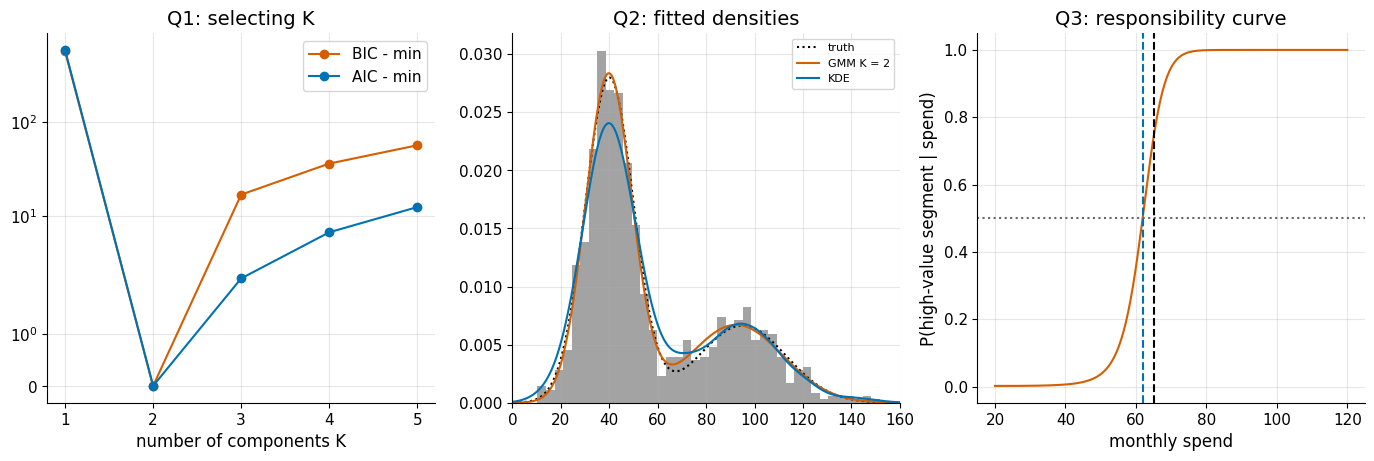

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); axes[0].plot(tab.index, tab["BIC"] - tab["BIC"].min(), "o-", color=HIGHLIGHT, label="BIC - min"); axes[0].plot(tab.index, tab["AIC"] - tab["AIC"].min(), "o-", color=MAIN, label="AIC - min"); axes[0].set_yscale("symlog"); axes[0].set_xlabel("number of components K"); axes[0].legend(); axes[0].set_title("Q1: selecting K")
axes[1].hist(trn, bins=40, density=True, color=NEUTRAL, alpha=0.6); axes[1].plot(xx, f_true(xx), color="black", linestyle=":", label="truth"); axes[1].plot(xx, np.exp(gmm_logpdf(xx, b)), color=HIGHLIGHT, label="GMM K = 2"); axes[1].plot(xx, kde(xx, trn, h_cv), color=MAIN, label="KDE"); axes[1].legend(fontsize=8); axes[1].set_xlim(0, 160); axes[1].set_title("Q2: fitted densities")
sx = np.linspace(20, 120, 300); axes[2].plot(sx, [resp(v) for v in sx], color=HIGHLIGHT); axes[2].axhline(0.5, color=NEUTRAL, linestyle=":"); axes[2].axvline(65, color="black", linestyle="--"); axes[2].axvline(x50, color=MAIN, linestyle="--"); axes[2].set_xlabel("monthly spend"); axes[2].set_ylabel("P(high-value segment | spend)"); axes[2].set_title("Q3: responsibility curve")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- **BIC, AIC and the held-out likelihood all choose $K=2$.** BIC is 9,522.6, **8,950.4**, 8,967.3, 8,986.5 and 9,007.0 for $K=1..5$; AIC is 9,512.8, **8,925.8**, 8,928.0, 8,932.5 and 8,938.3; the held-out log-likelihood per customer jumps from -4.806 to **-4.476** at $K=2$ and then stays flat (-4.477, -4.478, -4.478): extra components add parameters but no predictive power.
- The fitted segments are weights **0.676 / 0.324**, means **39.75 / 92.36** and SDs **9.56 / 19.29** against the truth 0.70 / 0.30, 40 / 95 and 10 / 18. The error of the high-value mean (2.6 dollars) is within sampling variation: a bootstrap interval for it is (89.5, 95.0).
- For a 65-dollar customer the true model gives a high-value probability of **0.575** (hand calculation) and the fitted model **0.740**; the spend with probability 1/2 is 61.9 (fitted) against 64.1 (true). Near the boundary between segments the responsibilities are very sensitive to the estimated spread, so an assignment at 65 should be labelled "uncertain".
- Held-out log-likelihood per customer: histogram -4.4880, KDE -4.4936, **GMM -4.4764**, true density -4.4742. The mixture is within 0.002 of the best possible, the KDE 0.019 and the histogram 0.014 below it. Customers simulated from the fitted mixture are statistically indistinguishable from the held-out 500 (KS distance 0.038, $p=0.47$).
- **Decision.** Use a two-segment mixture for the spend distribution and report segment probabilities rather than hard labels for customers between 55 and 75 dollars.

---
### Example 2: choosing the KDE bandwidth

**Scenario.** The same 1,000 training spends. Compare bandwidths from 1 to 30 by (a) leave-one-out cross-validated log-likelihood, (b) Silverman's rule, (c) the true integrated squared error (known here).

**Questions.** (1) Which bandwidth does leave-one-out cross-validation choose and how does it compare with Silverman's? (2) How much worse is the oversmoothed Silverman rule than the best bandwidth in held-out likelihood? (3) What does the true ISE say?

In [16]:
hs = np.geomspace(1, 30, 40); n_ = len(trn); D = (trn[:, None] - trn[None, :]); loo = []
for h in hs: Kmat = np.exp(-0.5 * (D / h) ** 2) / (h * np.sqrt(2 * np.pi)); np.fill_diagonal(Kmat, 0); loo.append(np.log(Kmat.sum(axis=1) / (n_ - 1)).mean())
loo = np.array(loo); h_loo = hs[np.argmax(loo)]; ise_c = np.array([np.trapezoid((kde(xx, trn, h) - f_true(xx)) ** 2, xx) for h in hs]); h_ise = hs[np.argmin(ise_c)]; hol = np.array([np.log(kde(tst, trn, h)).mean() for h in hs]); h_ho = hs[np.argmax(hol)]
print(f"Q1: LOO-CV bandwidth {h_loo:.2f} | Silverman {h_cv:.2f} | held-out best {h_ho:.2f} | ISE-optimal {h_ise:.2f}"); print(f"Q2: held-out log-lik per customer: LOO choice {np.log(kde(tst, trn, h_loo)).mean():.4f}, Silverman {np.log(kde(tst, trn, h_cv)).mean():.4f}, best on the grid {hol.max():.4f}")
print(f"Q3: ISE at the LOO choice {np.trapezoid((kde(xx, trn, h_loo) - f_true(xx)) ** 2, xx):.3e}, at Silverman {np.trapezoid((kde(xx, trn, h_cv) - f_true(xx)) ** 2, xx):.3e}, minimum {ise_c.min():.3e}")

Q1: LOO-CV bandwidth 3.70 | Silverman 6.35 | held-out best 3.11 | ISE-optimal 3.39
Q2: held-out log-lik per customer: LOO choice -4.4807, Silverman -4.4936, best on the grid -4.4805
Q3: ISE at the LOO choice 5.062e-05, at Silverman 2.500e-04, minimum 4.833e-05


### 12.5 Asserts

In [17]:
assert 2 < h_loo < 12 and 2 < h_cv < 12 and abs(np.log(h_loo / h_ise)) < 0.6 and np.log(kde(tst, trn, h_loo)).mean() > hol.max() - 0.03 and loo.max() > loo[0] and loo.max() > loo[-1]
print("all checks passed")

all checks passed


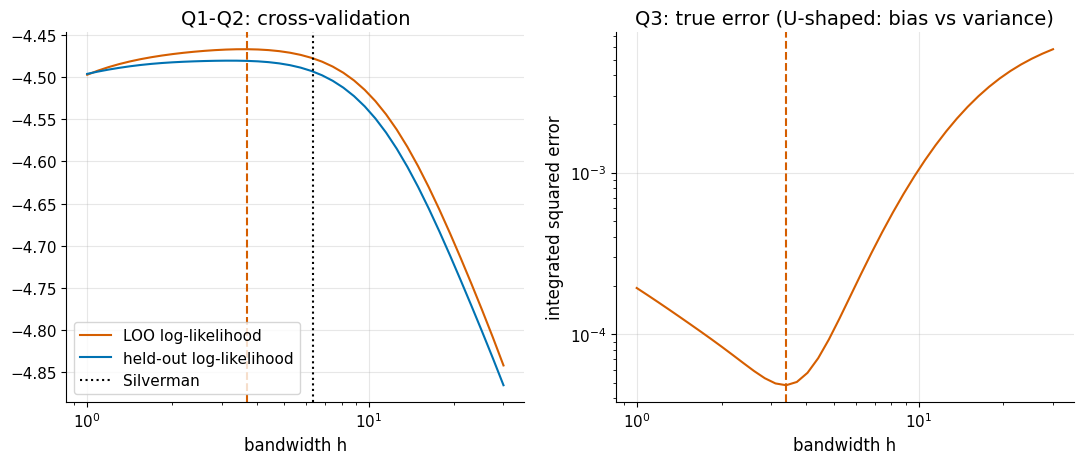

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].semilogx(hs, loo, color=HIGHLIGHT, label="LOO log-likelihood"); axes[0].semilogx(hs, hol, color=MAIN, label="held-out log-likelihood"); axes[0].axvline(h_loo, color=HIGHLIGHT, linestyle="--"); axes[0].axvline(h_cv, color="black", linestyle=":", label="Silverman"); axes[0].legend(); axes[0].set_xlabel("bandwidth h"); axes[0].set_title("Q1-Q2: cross-validation")
axes[1].loglog(hs, ise_c, color=HIGHLIGHT); axes[1].axvline(h_ise, color=HIGHLIGHT, linestyle="--"); axes[1].set_xlabel("bandwidth h"); axes[1].set_ylabel("integrated squared error"); axes[1].set_title("Q3: true error (U-shaped: bias vs variance)")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- Leave-one-out cross-validation picks **$h=3.70$**; the held-out best bandwidth is 3.11 and the ISE-optimal one (knowing the truth) 3.39, so cross-validation recovers the right neighbourhood without the truth. **Silverman's rule gives 6.35**, almost twice as wide.
- The price of that oversmoothing: held-out log-likelihood per customer **-4.4936** (Silverman) against -4.4807 (cross-validated) and -4.4805 (best on the grid), and the integrated squared error is **2.50e-4 against 5.06e-5**, five times larger. In 8.2 the same effect shows: with $h=1.5$ the ISE is 1.46e-4, with Silverman 2.67e-4 and with $h=25$ 4.91e-3 (the two segments merge into one hump).
- The optimal bandwidth shrinks like $n^{-1/5}$: the simulated slope over $n=100$ to 3,200 is **-0.223** (theory -0.2), with the best $h$ falling from 5.07 to 2.40, and the minimal MISE slope is -0.823 (theory -0.8).
- **Decision.** Silverman's rule assumes a single bell-shaped density; for multimodal data choose the bandwidth by cross-validation.

---
### Example 3: clusters with different shapes (covariance structure, GMM against k-means)

**Scenario.** 900 customers with two features (average basket in dollars and orders per month) from three segments: round ($\Sigma$ spherical), elongated with positive correlation, and elongated with negative correlation. Fit a GMM with spherical, diagonal and full covariances and k-means with $K=3$.

**Questions.** (1) Which covariance structure does BIC prefer? (2) What fraction of customers is assigned to the right segment by each method (after matching labels)? (3) How uncertain is the assignment for customers between clusters?

In [19]:
g = np.random.default_rng(31); specs = [(300, [0, 0], [[1, 0], [0, 1]]), (300, [6, 3], [[4, 3], [3, 4]]), (300, [6, -3], [[4, -3], [-3, 4]])]; X3 = np.vstack([g.multivariate_normal(m, C, n) for n, m, C in specs]); y3 = np.repeat([0, 1, 2], 300)
res = {cv: gmm(X3, 3, cov=cv, seed=4) for cv in ("spherical", "diag", "full")}; from itertools import permutations
def match_acc(lab, y): return max(np.mean(np.array(p)[lab] == y) for p in permutations(range(3)))
km_lab, km_mu = kmeans(X3, 3, seed=1); accs = {cv: match_acc(np.argmax(f["R"], axis=1), y3) for cv, f in res.items()}; accs["k-means"] = match_acc(km_lab, y3)
print(pd.DataFrame({cv: {"parameters": f["npar"], "log-likelihood": f["ll"], "BIC": f["bic"], "accuracy": accs[cv]} for cv, f in res.items()}).T.round(3).to_string()); print(f"k-means accuracy {accs['k-means']:.4f}")
Rf = res["full"]["R"]; unc = 1 - Rf.max(axis=1); print(f"Q3: customers with maximum responsibility below 0.9: {np.mean(Rf.max(axis=1) < 0.9):.3f}, below 0.6: {np.mean(Rf.max(axis=1) < 0.6):.3f}; mean assignment uncertainty {unc.mean():.4f}")

           parameters  log-likelihood       BIC  accuracy
spherical        11.0       -4247.439  8569.705     0.926
diag             14.0       -4205.503  8506.240     0.834
full             17.0       -4024.030  8163.701     0.940
k-means accuracy 0.8789
Q3: customers with maximum responsibility below 0.9: 0.164, below 0.6: 0.053; mean assignment uncertainty 0.0599


### 12.6 Asserts

In [20]:
assert min(res, key=lambda c: res[c]["bic"]) == "full" and accs["full"] > accs["k-means"] and accs["full"] > 0.9
print("all checks passed")

all checks passed


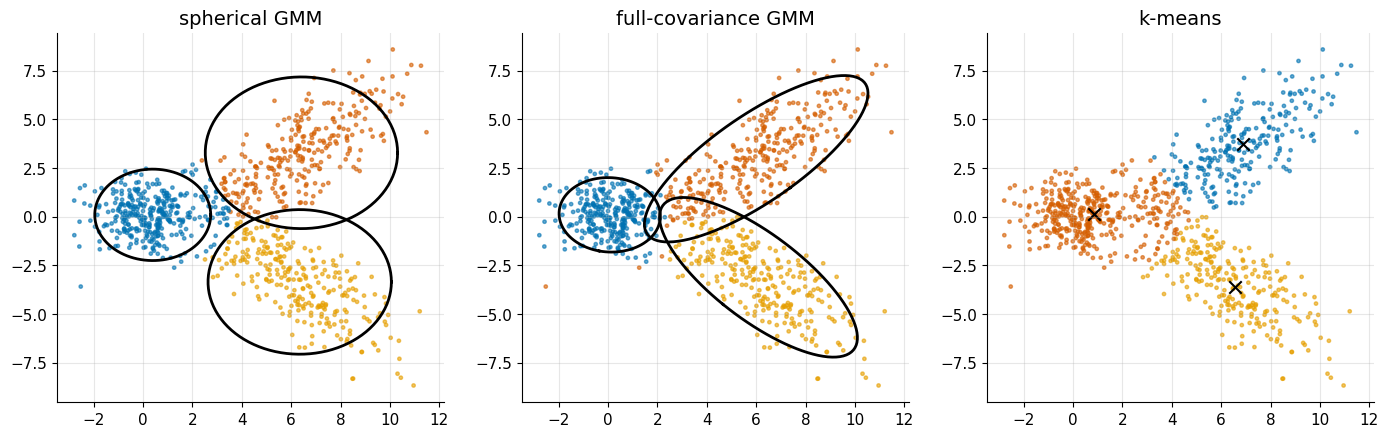

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); cols = [MAIN, SIM, HIGHLIGHT]
def ell(ax, mu, S, colr):
    w, v = np.linalg.eigh(S); ang = np.linspace(0, 2 * np.pi, 100); pts = (v @ (np.sqrt(w)[:, None] * 2 * np.array([np.cos(ang), np.sin(ang)]))).T + mu; ax.plot(pts[:, 0], pts[:, 1], color=colr, linewidth=2)
for ax, (nm, lab) in zip(axes[:2], [("spherical GMM", np.argmax(res["spherical"]["R"], axis=1)), ("full-covariance GMM", np.argmax(res["full"]["R"], axis=1))]):
    ax.scatter(X3[:, 0], X3[:, 1], c=[cols[k] for k in lab], s=6, alpha=0.6); f_ = res["spherical" if "spherical" in nm else "full"]
    for k in range(3): ell(ax, f_["mu"][k], f_["S"][k], "black")
    ax.set_title(nm)
axes[2].scatter(X3[:, 0], X3[:, 1], c=[cols[k] for k in km_lab], s=6, alpha=0.6); axes[2].scatter(km_mu[:, 0], km_mu[:, 1], marker="x", color="black", s=80); axes[2].set_title("k-means")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- BIC clearly prefers the **full covariance** model: 8,163.7 against 8,506.2 (diagonal, 14 parameters) and 8,569.7 (spherical, 11 parameters); the 3 to 6 extra parameters of the full model improve the log-likelihood by 181 and 223 nats.
- Segment recovery (after matching labels): **full 94.0 %**, spherical 92.6 %, **k-means 87.9 %** and diagonal 83.4 %. The diagonal model cannot represent the two correlated clusters (correlations +0.75 and -0.75) and splits them wrongly, which is worse than the spherical one in this run; k-means with its round clusters cuts the elongated segments.
- Even the best model is unsure for some customers: **16.4 %** have a maximum responsibility below 0.9 and **5.3 %** below 0.6 (customers between the two elongated clusters).
- **Decision.** Use the full-covariance mixture and carry the responsibilities forward (for example as weights in a marketing campaign) instead of forcing hard labels; use k-means only when clusters are known to be round and well separated.

---
### Example 4: a fitted density as a generator and as an anomaly detector

**Scenario.** Using the 2-feature mixture of Example 3 (full covariance) we (a) **generate** 5,000 synthetic customers and check them against the real ones, and (b) flag the 1 % of customers with the **lowest density** as anomalies, then see how a few injected fraudulent customers (very high basket, many orders) score.

**Questions.** (1) Do the means, standard deviations and correlation of the synthetic sample match the real data? (2) What density threshold flags 1 % of real customers, and what share of 30 injected anomalies does it catch? (3) How many real customers are falsely flagged (by construction 1 %)?

In [22]:
f = res["full"]; g = np.random.default_rng(41); kk = g.choice(3, 5000, p=f["pi"]); syn = np.array([g.multivariate_normal(f["mu"][k], f["S"][k]) for k in kk])
print("Q1: real mean", X3.mean(axis=0).round(3), "synthetic", syn.mean(axis=0).round(3), "| SD", X3.std(axis=0).round(3), syn.std(axis=0).round(3), "| correlation", np.corrcoef(X3.T)[0, 1].round(3), np.corrcoef(syn.T)[0, 1].round(3))
lr = gmm_logpdf(X3, f); thr = np.quantile(lr, 0.01); anom = np.column_stack([g.uniform(10, 16, 30), g.uniform(-9, 9, 30)]); la = gmm_logpdf(anom, f)
print(f"Q2: log-density threshold (1% of customers) {thr:.2f} | injected anomalies below the threshold: {np.mean(la < thr):.3f} | median log-density: real {np.median(lr):.2f}, anomalies {np.median(la):.2f}"); print(f"Q3: real customers flagged: {np.mean(lr < thr):.4f}")

Q1: real mean [4.078 0.05 ] synthetic [4.08  0.049] | SD [3.362 3.075] [3.36  3.073] | correlation 0.01 0.018
Q2: log-density threshold (1% of customers) -7.51 | injected anomalies below the threshold: 0.867 | median log-density: real -4.34, anomalies -16.49
Q3: real customers flagged: 0.0100


### 12.7 Asserts

In [23]:
assert np.abs(X3.mean(axis=0) - syn.mean(axis=0)).max() < 0.2 and abs(np.corrcoef(X3.T)[0, 1] - np.corrcoef(syn.T)[0, 1]) < 0.05 and np.mean(la < thr) > 0.8 and abs(np.mean(lr < thr) - 0.01) < 0.005
print("all checks passed")

all checks passed


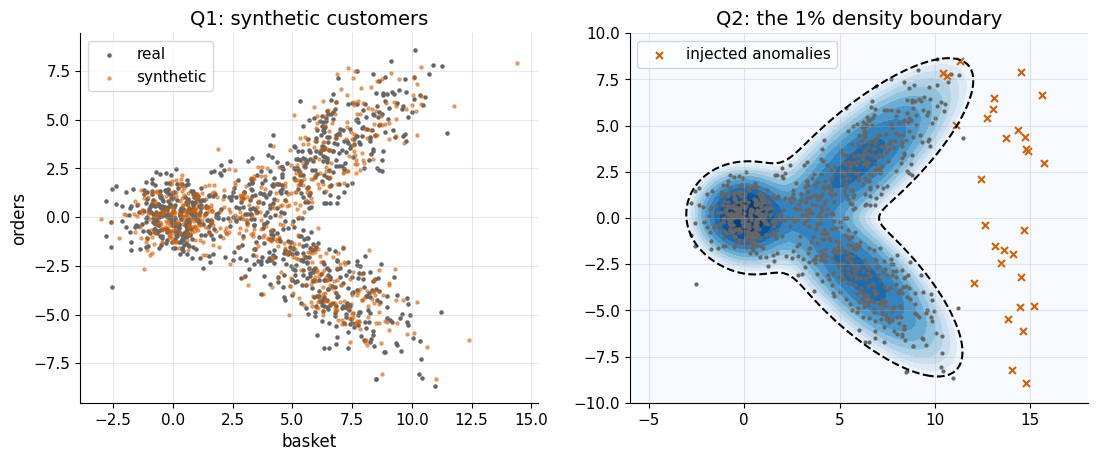

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].scatter(X3[:, 0], X3[:, 1], s=5, color=NEUTRAL, label="real"); axes[0].scatter(syn[:600, 0], syn[:600, 1], s=5, color=HIGHLIGHT, alpha=0.5, label="synthetic"); axes[0].legend(); axes[0].set_xlabel("basket"); axes[0].set_ylabel("orders"); axes[0].set_title("Q1: synthetic customers")
GG1, GG2 = np.meshgrid(np.linspace(-6, 18, 120), np.linspace(-10, 10, 120)); Lg = gmm_logpdf(np.column_stack([GG1.ravel(), GG2.ravel()]), f).reshape(GG1.shape); axes[1].contourf(GG1, GG2, Lg, levels=np.linspace(thr, Lg.max(), 12), cmap="Blues", extend="min"); axes[1].contour(GG1, GG2, Lg, levels=[thr], colors="black"); axes[1].scatter(X3[:, 0], X3[:, 1], s=4, color=NEUTRAL); axes[1].scatter(anom[:, 0], anom[:, 1], s=25, color=HIGHLIGHT, marker="x", label="injected anomalies"); axes[1].legend(); axes[1].set_title("Q2: the 1% density boundary")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- The synthetic sample matches the real data: means (4.080, 0.049) against (4.078, 0.050), SDs (3.360, 3.073) against (3.362, 3.075) and correlation 0.018 against 0.010.
- The 1 % lowest-density threshold is a log-density of **-7.51**; it flags exactly 1.00 % of the real customers and **86.7 %** of the 30 injected anomalies (median log-density -16.49 against -4.34 for real customers). The anomalies that escape are the ones whose basket is only moderately high and lie within reach of the tail of the right-hand cluster.
- **Decision.** A fitted mixture is a cheap generator of realistic test data and a cheap anomaly score; choose the threshold from the false-alarm budget (here 1 %) and report the detection rate separately.

## 13. Where it is used

### Statistics
- **Nonparametric density estimation** (KDE, with cross-validated bandwidths), **mixture models** for heterogeneous populations, latent-class analysis, **EM** as the standard tool for missing data and hidden variables, model selection with AIC and BIC.

### Data science
- **Customer segmentation** with soft memberships, **anomaly and fraud detection** from low density, **synthetic data generation** and imputation, distribution checks and fitting for simulation inputs, exploratory plots (KDE) with honest bandwidth choices.

### ML and AI
- **Gaussian mixtures in speech and image models**, initialisation of **mixture-density networks**, **variational inference** and the ELBO (the EM decomposition in 5.2 is the blueprint of VAEs, 09_08), **topic models** and clustering of embeddings, density-based novelty detection in monitoring pipelines.

## 14. Common pitfalls and misconceptions

- **Trusting a histogram's shape:** bin width and origin change it (8.1); show a KDE or several widths.
- **Using a default bandwidth blindly:** Silverman's rule oversmooths multimodal data; cross-validate (Example 2).
- **Choosing $K$ by training likelihood:** it always rises with $K$; use BIC, AIC or held-out likelihood.
- **Single EM run:** EM finds local maxima; use several seeds and keep the best likelihood; add a variance floor against collapse onto a point.
- **Assuming clusters are round:** spherical covariance (and k-means) splits elongated clusters wrongly (Example 3).
- **Reading responsibilities as certainty:** they are conditional on the fitted model being right; customers between clusters have uncertain labels.
- **KDE in high dimension:** it needs enormous samples; use a structured model (GMM, normalising flows) instead.
- **Label switching:** component 1 in one run can be component 2 in another; compare sorted parameters.

## 15. Exercises

1. Compute by hand the responsibility of the high-value segment for a spend of 80 under the fitted model of Example 1 using the true parameters, and the spend at which the two segments are equally likely.
2. Use Silverman's rule to compute the bandwidth for $n=500$ points with $s=12$ and IQR 15.
3. Fit a 2-component GMM to the first 100 customers only. How do the estimates and their uncertainty compare with the full 1,000?
4. Count the free parameters of a full-covariance GMM with $K=4$ in $d=5$ dimensions and compute its BIC penalty for $n=2{,}000$.
5. Implement a bootstrap (200 resamples) to get a 95 % confidence interval for the mean of the high-value segment in Example 1.
6. (Harder) Show that with a variance floor of 0 and a component centred exactly on one data point the likelihood can be made arbitrarily large, and describe how the floor prevents it.

Solutions are at the end.

## 16. Summary table

| Method | Model | Controls | Weakness |
|---|---|---|---|
| Histogram | piecewise constant | bin width, origin | depends on both |
| KDE | sum of bumps | bandwidth $h\propto n^{-1/5}$ | curse of dimensionality |
| GMM | $\sum\pi_kN(\mu_k,\Sigma_k)$ | $K$, covariance type | local maxima, assumes bells |
| EM | E: responsibilities; M: weighted MLE | iterations | monotone but local |
| Selection | BIC, AIC, held-out likelihood | | |
| k-means | hard, spherical limit | $K$ | round clusters only |
| tools | `gaussian_kde`, `multivariate_normal`, `logsumexp` | | |

## Solutions

In [25]:
r80 = 0.3 * stats.norm.pdf(80, 95, 18) / (0.3 * stats.norm.pdf(80, 95, 18) + 0.7 * stats.norm.pdf(80, 40, 10)); print(f"1: P(high-value | 80) = {r80:.4f}; equal-likelihood spend {brentq(lambda v: 0.3 * stats.norm.pdf(v, 95, 18) - 0.7 * stats.norm.pdf(v, 40, 10), 40, 95):.2f}")
print(f"2: h = 0.9 * min(12, 15 / 1.34) * 500^(-0.2) = {0.9 * min(12, 15 / 1.34) * 500 ** -0.2:.3f}")
f100 = gmm(trn[:100], 2, seed=1); o100 = np.argsort(f100["mu"].ravel()); print("3: n = 100: weights", f100["pi"][o100].round(3), "means", f100["mu"].ravel()[o100].round(2), "sds", np.sqrt(f100["S"].ravel()[o100]).round(2), "(n = 1000:", b["pi"][o].round(3), b["mu"].ravel()[o].round(2), ")")
p4 = (4 - 1) + 4 * 5 + 4 * 5 * 6 // 2; print(f"4: parameters {p4}, BIC penalty {p4 * np.log(2000):.1f}")
gb = np.random.default_rng(5); bm = []
for _ in range(200): sm_ = gmm(trn[gb.integers(0, len(trn), len(trn))], 2, seed=1); bm.append(sm_["mu"].ravel()[np.argmax(sm_["mu"].ravel())])
print(f"5: bootstrap 95% interval for the high-value mean: ({np.quantile(bm, 0.025):.2f}, {np.quantile(bm, 0.975):.2f}) | point estimate {b['mu'].max():.2f}")
print("6: a component N(x_1, s^2) contributes 1 / (s sqrt(2 pi)) to the density at x_1, which grows without bound as s -> 0 while the other points keep a positive density: the likelihood diverges; the floor s^2 >= 1e-6 caps it.")

1: P(high-value | 80) = 0.9980; equal-likelihood spend 64.11
2: h = 0.9 * min(12, 15 / 1.34) * 500^(-0.2) = 2.907
3: n = 100: weights [0.595 0.405] means [38.43 91.92] sds [ 8.59 18.35] (n = 1000: [0.676 0.324] [39.75 92.36] )
4: parameters 83, BIC penalty 630.9


5: bootstrap 95% interval for the high-value mean: (89.51, 95.04) | point estimate 92.36
6: a component N(x_1, s^2) contributes 1 / (s sqrt(2 pi)) to the density at x_1, which grows without bound as s -> 0 while the other points keep a positive density: the likelihood diverges; the floor s^2 >= 1e-6 caps it.


**1.** $P(\text{high-value}\mid80)=$ **0.998**; the two segments are equally likely at a spend of **64.11** dollars with the true parameters.

**2.** $h=0.9\min(12,\,15/1.34)\cdot500^{-0.2}=0.9\cdot11.19\cdot0.2885=$ **2.907**.

**3.** With only 100 customers the fit is noticeably worse: weights **0.595 / 0.405** (truth 0.70 / 0.30), means 38.4 / 91.9, SDs 8.6 / 18.4. The segment weights are the least stable parameters; with 1,000 customers they are 0.676 / 0.324.

**4.** $(K-1)+Kd+Kd(d+1)/2=3+20+60=$ **83** parameters, so the BIC penalty is $83\ln2000=$ **630.9**.

**5.** The bootstrap 95 % interval for the high-value mean is **(89.5, 95.0)** around the estimate 92.36; it contains the true 95.

**6.** A component centred on one data point $x_1$ with variance $s^2$ contributes $1/(s\sqrt{2\pi})$ to the density at $x_1$, which grows without bound as $s\to0$, while the other points keep a positive density from the remaining components: the likelihood diverges. The floor $s^2\ge10^{-6}$ caps this contribution.